# Lab 2 — Spam Classification and Outlier Detection

**Student Name:** Ubaid Ullah  
**Student ID:** 9110715  
**Course:** AI Algorithms and Mathematics

## Objective

This lab explores probability-based classification and statistical
methods for detecting and removing outliers.

### Part A — Spam Classification
Train and compare Gaussian Naive Bayes and Multinomial Naive Bayes
classifiers to predict whether a message is spam or not spam.

### Part B — Airbnb Price Outlier Detection
Analyze New York City Airbnb prices using statistical methods,
identify outliers, and create a cleaned dataset.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the repository's practical_labs directory.
current_dir = Path.cwd()
search_dirs = [current_dir, *current_dir.parents]

repo_dir = next(
    (folder for folder in search_dirs
     if (folder / "practical_labs" / "Lab2_dataset.csv").exists()),
    None
)

if repo_dir is None:
    raise FileNotFoundError(
        "Could not find practical_labs/Lab2_dataset.csv. "
        "Please check your repository folder."
    )

# Load the spam classification dataset.
file_path = repo_dir / "practical_labs" / "Lab2_dataset.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

display(df.head())

Dataset shape: (5171, 4)

Column names: ['Unnamed: 0', 'label', 'text', 'label_num']


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


## Part A — Spam Classification

### 1. Dataset Exploration and Data Quality

The dataset contains email messages labeled as spam or ham.

Before training the classifiers, we examine the dataset structure,
class distribution, missing values, duplicate messages, and label
consistency.

These checks help ensure that the data is suitable for machine
learning and identify any preprocessing requirements.

In [2]:
# Display dataset information
print("Dataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check duplicate email messages
print("\nDuplicate Emails:")
print(df.duplicated(subset=["text"]).sum())

# Check empty email messages
print("\nEmpty Email Messages:")
print(df["text"].fillna("").str.strip().eq("").sum())

# Check distribution of spam and ham
print("\nEmail Class Distribution:")
print(df["label"].value_counts())

print("\nClass Distribution (%):")
print(df["label"].value_counts(normalize=True).mul(100).round(2))

# Verify numerical labels
print("\nLabel Consistency:")
display(pd.crosstab(df["label"], df["label_num"]))

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB

Missing Values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64

Duplicate Emails:
178

Empty Email Messages:
0

Email Class Distribution:
label
ham     3672
spam    1499
Name: count, dtype: int64

Class Distribution (%):
label
ham     71.01
spam    28.99
Name: proportion, dtype: float64

Label Consistency:


label_num,0,1
label,,
ham,3672,0
spam,0,1499


### 2. Exploratory Data Analysis Findings

The dataset contains 5,171 email messages.

**Key Findings:**

- Missing Values: 0
- Empty Messages: 0
- Duplicate Email Messages: 178
- Ham Emails: 3,672 (71.01%)
- Spam Emails: 1,499 (28.99%)
- Label Encoding: Ham = 0, Spam = 1

**Interpretation:**

The dataset contains more ham messages than spam messages,
making the classes moderately imbalanced.

No missing or empty messages were found. However, 178
duplicate email messages were identified.

Duplicate messages will be removed before splitting the
dataset to reduce the risk of data leakage.

Because the classes are imbalanced, we will evaluate the
models using accuracy, precision, recall, F1-score, and
confusion matrices.

In [3]:
# Check whether identical emails have conflicting labels
conflicting_labels = (
    df.groupby("text")["label_num"]
    .nunique()
    .gt(1)
    .sum()
)

print("Emails with conflicting labels:", conflicting_labels)

if conflicting_labels > 0:
    raise ValueError(
        "Identical emails have conflicting labels. "
        "Review these records before cleaning."
    )

# Remove duplicate email messages
df_clean = df.drop_duplicates(subset=["text"]).copy()

# Remove unnecessary index column
df_clean = df_clean.drop(columns=["Unnamed: 0"])

# Reset index
df_clean = df_clean.reset_index(drop=True)

# Display cleaning results
print("\nOriginal dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicates removed:", len(df) - len(df_clean))

print("\nClass Distribution After Cleaning:")
print(df_clean["label"].value_counts())

print("\nRemaining duplicate emails:",
      df_clean.duplicated(subset=["text"]).sum())

display(df_clean.head())

Emails with conflicting labels: 0

Original dataset shape: (5171, 4)
Cleaned dataset shape: (4993, 3)
Duplicates removed: 178

Class Distribution After Cleaning:
label
ham     3531
spam    1462
Name: count, dtype: int64

Remaining duplicate emails: 0


,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\nthis deal is to ...,0


### 3. Data Cleaning Results

After removing 178 duplicate emails, 4,993 unique email
messages remain.

- Ham emails: 3,531
- Spam emails: 1,462
- Remaining duplicates: 0
- Conflicting labels: 0

The cleaned dataset will be used for model training
and evaluation.

### 4. Train-Test Split

The cleaned dataset is divided into:

- 80% training data
- 20% testing data

Stratified splitting is applied to preserve the
proportion of spam and ham messages in both sets.

A random state of 42 is used to ensure reproducibility.

In [4]:
from sklearn.model_selection import train_test_split

# Features (email text)
X = df_clean["text"]

# Target (0 = ham, 1 = spam)
y = df_clean["label_num"]

# Split dataset: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes
print("Total emails:", len(X))
print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

# Check class distribution
print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

# Check class percentages
print("\nTraining Class Percentages:")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nTesting Class Percentages:")
print(y_test.value_counts(normalize=True).mul(100).round(2))

Total emails: 4993
Training emails: 3994
Testing emails: 999

Training Class Distribution:
label_num
0    2825
1    1169
Name: count, dtype: int64

Testing Class Distribution:
label_num
0    706
1    293
Name: count, dtype: int64

Training Class Percentages:
label_num
0    70.73
1    29.27
Name: proportion, dtype: float64

Testing Class Percentages:
label_num
0    70.67
1    29.33
Name: proportion, dtype: float64


### 5. Text Feature Extraction Using CountVectorizer

Machine learning classifiers require numerical features
rather than raw text.

CountVectorizer converts each email into a numerical
representation based on word frequencies.

The following preprocessing settings are used:

- Convert text to lowercase (default behavior).
- Remove common English stop words.
- Keep a maximum of 2,000 features.
- Ignore words appearing in fewer than two training emails.

The vectorizer is fitted only on the training data to
prevent information leakage from the test dataset.

The same numerical features will be used to train
and compare Gaussian Naive Bayes and Multinomial
Naive Bayes classifiers.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer

# Initialize text vectorizer
vectorizer = CountVectorizer(
    max_features=2000,
    min_df=2,
    stop_words="english"
)

# Learn vocabulary from training data only
X_train_counts = vectorizer.fit_transform(X_train)

# Transform test data using the same vocabulary
X_test_counts = vectorizer.transform(X_test)

# Display resulting shapes
print("Training Feature Matrix:", X_train_counts.shape)
print("Testing Feature Matrix:", X_test_counts.shape)

# Display vocabulary size
print("\nVocabulary Size:", len(vectorizer.vocabulary_))

# Show sample extracted words
print("\nFirst 20 Vocabulary Words:")
print(vectorizer.get_feature_names_out()[:20])

# Confirm non-negative feature counts
print("\nMinimum Feature Count:")
print(X_train_counts.min())

Training Feature Matrix: (3994, 2000)
Testing Feature Matrix: (999, 2000)

Vocabulary Size: 2000

First 20 Vocabulary Words:
['00' '000' '000000' '01' '012' '02' '027' '03' '04' '0435' '05' '06' '07'
 '08' '09' '098' '0986725' '10' '100' '1000']

Minimum Feature Count:
0


### 6. Training Naive Bayes Classification Models

Naive Bayes is a probabilistic machine learning algorithm
based on Bayes' theorem. It assumes that features are
conditionally independent given the class label.

Two classifiers are trained and compared:

**Gaussian Naive Bayes**

Gaussian Naive Bayes assumes that numerical features
follow a normal distribution within each class.

**Multinomial Naive Bayes**

Multinomial Naive Bayes is designed for discrete
count-based features, making it suitable for text
classification using word frequencies.

Both models are trained using the same training
dataset to ensure a fair comparison.

Gaussian Naive Bayes requires a dense feature matrix,
while Multinomial Naive Bayes supports sparse matrices.

The trained models will be evaluated using the
previously separated test dataset.

In [6]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB

# -------------------------------------
# Model 1: Gaussian Naive Bayes
# -------------------------------------

gaussian_nb = GaussianNB()

# GaussianNB requires a dense matrix
X_train_dense = X_train_counts.toarray()

# Train Gaussian Naive Bayes
gaussian_nb.fit(X_train_dense, y_train)

print("Gaussian Naive Bayes trained successfully!")


# -------------------------------------
# Model 2: Multinomial Naive Bayes
# -------------------------------------

multinomial_nb = MultinomialNB()

# MultinomialNB supports sparse matrices
multinomial_nb.fit(X_train_counts, y_train)

print("Multinomial Naive Bayes trained successfully!")


# -------------------------------------
# Verify trained models
# -------------------------------------

print("\nGaussian NB Classes:", gaussian_nb.classes_)
print("Multinomial NB Classes:", multinomial_nb.classes_)

print("\nBoth models are ready for evaluation.")

Gaussian Naive Bayes trained successfully!
Multinomial Naive Bayes trained successfully!

Gaussian NB Classes: [0 1]
Multinomial NB Classes: [0 1]

Both models are ready for evaluation.


### 7. Model Evaluation and Comparison

Both Gaussian Naive Bayes and Multinomial Naive Bayes
are evaluated using the same 999 testing emails.

The following evaluation metrics are used:

- **Accuracy:** Overall percentage of correct predictions.
- **Precision:** Proportion of predicted spam emails that are actually spam.
- **Recall:** Proportion of actual spam emails correctly detected.
- **F1-score:** Harmonic mean of precision and recall.
- **Confusion Matrix:** Shows correct and incorrect classifications.

Since the dataset contains more ham than spam,
accuracy alone may be misleading.

The models will be compared using all these metrics
to determine which performs better for spam detection.

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1-score
0,Gaussian Naive Bayes,0.9479,0.8731,0.9625,0.9156
1,Multinomial Naive Bayes,0.9469,0.8704,0.9625,0.9141



Gaussian Naive Bayes Report:
              precision    recall  f1-score   support

         Ham       0.98      0.94      0.96       706
        Spam       0.87      0.96      0.92       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999


Multinomial Naive Bayes Report:
              precision    recall  f1-score   support

         Ham       0.98      0.94      0.96       706
        Spam       0.87      0.96      0.91       293

    accuracy                           0.95       999
   macro avg       0.93      0.95      0.94       999
weighted avg       0.95      0.95      0.95       999



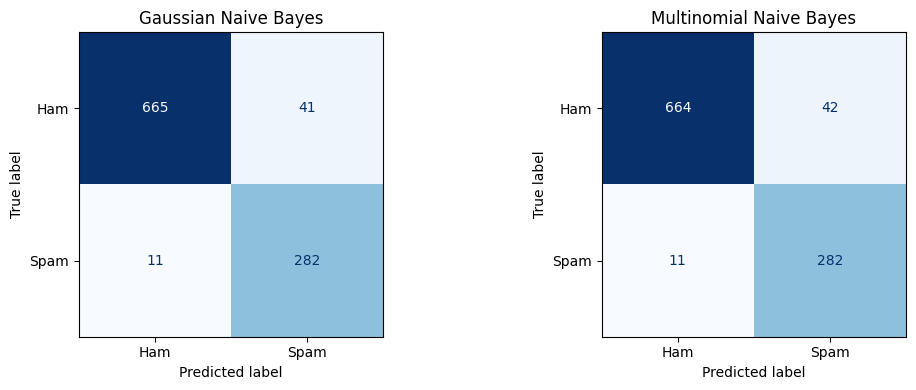

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# -------------------------------------
# 1. Generate predictions
# -------------------------------------

# Gaussian NB requires dense test data
X_test_dense = X_test_counts.toarray()

y_pred_gaussian = gaussian_nb.predict(X_test_dense)

# Multinomial NB accepts sparse test data
y_pred_multinomial = multinomial_nb.predict(X_test_counts)


# -------------------------------------
# 2. Compare performance
# -------------------------------------

results = []

for name, predictions in [
    ("Gaussian Naive Bayes", y_pred_gaussian),
    ("Multinomial Naive Bayes", y_pred_multinomial)
]:
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df.round(4))


# -------------------------------------
# 3. Detailed classification reports
# -------------------------------------

print("\nGaussian Naive Bayes Report:")
print(classification_report(
    y_test,
    y_pred_gaussian,
    target_names=["Ham", "Spam"]
))

print("\nMultinomial Naive Bayes Report:")
print(classification_report(
    y_test,
    y_pred_multinomial,
    target_names=["Ham", "Spam"]
))


# -------------------------------------
# 4. Visualize confusion matrices
# -------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

models = [
    ("Gaussian Naive Bayes", y_pred_gaussian),
    ("Multinomial Naive Bayes", y_pred_multinomial)
]

for ax, (name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

### 8. Model Comparison and Observations

Both Naive Bayes classifiers performed well on the test dataset.

| Metric | Gaussian NB | Multinomial NB |
|---|---:|---:|
| Accuracy | 94.79% | 94.69% |
| Precision (Spam) | 87.31% | 87.04% |
| Recall (Spam) | 96.25% | 96.25% |
| F1-score (Spam) | 91.56% | 91.41% |

**Confusion Matrix Observations**

Gaussian Naive Bayes:
- Correctly classified ham: 665
- Correctly classified spam: 282
- Ham incorrectly classified as spam: 41
- Spam incorrectly classified as ham: 11

Multinomial Naive Bayes:
- Correctly classified ham: 664
- Correctly classified spam: 282
- Ham incorrectly classified as spam: 42
- Spam incorrectly classified as ham: 11

**Conclusion**

Gaussian Naive Bayes achieved slightly higher accuracy,
precision, and F1-score than Multinomial Naive Bayes.

Both models achieved the same spam recall of 96.25%,
correctly identifying 282 out of 293 spam emails.

Gaussian Naive Bayes made one fewer classification error
than Multinomial Naive Bayes.

Therefore, Gaussian Naive Bayes performed marginally
better on this particular test dataset.

However, the difference is very small and does not
establish that Gaussian Naive Bayes is generally superior.

Multinomial Naive Bayes remains a suitable model for
text classification because it is designed for
count-based features and efficiently handles sparse data.

Further evaluation using cross-validation could help
determine whether this small performance difference
is consistent across different data splits.

### 9. Predictions on Unseen Test Emails

The Gaussian Naive Bayes classifier is selected for
demonstration because it achieved the slightly higher
F1-score and accuracy on the test dataset.

Five emails from the test dataset are selected for
prediction.

The predicted labels are compared with the actual
labels to demonstrate how the trained classifier
performs on unseen email messages.

- 0 represents Ham.
- 1 represents Spam.

In [8]:
# Select the first 5 test emails
sample_emails = X_test.iloc[:5]
sample_actual = y_test.iloc[:5]

# Transform using the existing training vocabulary
sample_features = vectorizer.transform(sample_emails)

# Predict using the trained Gaussian NB model
sample_predictions = gaussian_nb.predict(
    sample_features.toarray()
)

# Display results
prediction_results = pd.DataFrame({
    "Email Preview": sample_emails.str[:100].values,
    "Actual Label": sample_actual.map(
        {0: "Ham", 1: "Spam"}
    ).values,
    "Predicted Label": [
        "Spam" if prediction == 1 else "Ham"
        for prediction in sample_predictions
    ]
})

prediction_results["Correct"] = (
    prediction_results["Actual Label"] ==
    prediction_results["Predicted Label"]
)

print("Gaussian Naive Bayes — Sample Predictions:")
display(prediction_results)

print(
    "\nCorrect Predictions:",
    prediction_results["Correct"].sum(),
    "out of",
    len(prediction_results)
)

Gaussian Naive Bayes — Sample Predictions:


,Email Preview,Actual Label,Predicted Label,Correct
0,"Subject: frontrea plant , gas\nwhen : wednesda...",Ham,Spam,False
1,Subject: news\nat least two bids seen for enro...,Ham,Ham,True
2,"Subject: quailty web solutions , involutory\no...",Spam,Spam,True
3,Subject: txu fuels / sds nomination for decemb...,Ham,Ham,True
4,Subject: use the links to get more information...,Spam,Spam,True



Correct Predictions: 4 out of 5


### 10. Part A — Final Conclusion

In Part A, the Lab2 email dataset was used to train
and evaluate two probabilistic classification models:
Gaussian Naive Bayes and Multinomial Naive Bayes.

**Data Preparation:**
- Original dataset: 5,171 emails
- Duplicate emails removed: 178
- Cleaned dataset: 4,993 emails
- Training dataset: 3,994 emails
- Testing dataset: 999 emails
- Text converted into 2,000 word-count features

**Model Performance:**
- Gaussian Naive Bayes accuracy: 94.79%
- Multinomial Naive Bayes accuracy: 94.69%

Gaussian Naive Bayes performed slightly better on
this test dataset, although the difference was small.

Both models achieved 96.25% recall for spam detection.

**Prediction Demonstration:**

Gaussian Naive Bayes correctly classified 4 out of
5 selected test emails. One legitimate email was
incorrectly classified as spam (false positive).

The five-email demonstration does not replace the
overall evaluation using all 999 testing emails.

**Final Observation:**

Both classifiers demonstrated strong spam detection
performance. The results show how probability-based
machine learning algorithms can classify emails using
numerical word-frequency features.

---

# Part B — Airbnb NYC Price Outlier Detection

## 1. Objective

The objective of Part B is to identify and remove
outliers from New York City Airbnb nightly prices.

The analysis will explore different statistical methods,
including:

- Mean and standard deviation
- Median and median absolute deviation (MAD)
- Percentile-based filtering
- Interquartile range (IQR)
- Z-score

The methods will be compared to understand how they
identify unusually high or low prices.

The final result will be a cleaned Airbnb dataset
with clearly defined outlier-removal criteria.

In [9]:
# Load the Airbnb NYC dataset
airbnb_path = repo_dir / "practical_labs" / "AB_NYC_2019.csv"

df_airbnb = pd.read_csv(airbnb_path)

# Display dataset shape and structure
print("Airbnb Dataset Shape:", df_airbnb.shape)

print("\nColumn Names:")
print(df_airbnb.columns.tolist())

print("\nDataset Information:")
df_airbnb.info()

print("\nFirst Five Records:")
display(df_airbnb.head())

# Check missing values
print("\nMissing Values:")
print(df_airbnb.isnull().sum())

# Check duplicates
print("\nDuplicate Rows:")
print(df_airbnb.duplicated().sum())

Airbnb Dataset Shape: (48895, 16)

Column Names:
['id', 'name', 'host_id', 'host_name', 'neighbourhood_group', 'neighbourhood', 'latitude', 'longitude', 'room_type', 'price', 'minimum_nights', 'number_of_reviews', 'last_review', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude             

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0



Missing Values:
id                                    0
name                                 16
host_id                               0
host_name                            21
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                 10052
calculated_host_listings_count        0
availability_365                      0
dtype: int64

Duplicate Rows:
0


## 2. Initial Price Analysis

Before removing outliers, we examine the distribution
of Airbnb nightly prices.

The following statistical measures are calculated:

- Mean: Average nightly price.
- Median: Middle nightly price.
- Standard Deviation: Variation in prices.
- Minimum and Maximum: Lowest and highest prices.
- Quartiles (Q1, Q2, Q3): Divide the data into four parts.
- Percentiles: Show the price below which a given
  percentage of listings falls.

We also check zero or negative prices because these
may represent invalid or unusual listing values.

No outliers are removed at this stage.

In [10]:
# -------------------------------------
# 1. Price summary statistics
# -------------------------------------

print("Airbnb Price Summary:")
display(df_airbnb["price"].describe())

# -------------------------------------
# 2. Statistical measures
# -------------------------------------

price_mean = df_airbnb["price"].mean()
price_median = df_airbnb["price"].median()
price_std = df_airbnb["price"].std()

q1 = df_airbnb["price"].quantile(0.25)
q3 = df_airbnb["price"].quantile(0.75)
iqr = q3 - q1

print("\nStatistical Measures:")
print(f"Mean: ${price_mean:.2f}")
print(f"Median: ${price_median:.2f}")
print(f"Standard Deviation: ${price_std:.2f}")
print(f"Q1 (25th Percentile): ${q1:.2f}")
print(f"Q2 (Median): ${price_median:.2f}")
print(f"Q3 (75th Percentile): ${q3:.2f}")
print(f"IQR: ${iqr:.2f}")

# -------------------------------------
# 3. Additional percentiles
# -------------------------------------

print("\nPrice Percentiles:")
display(
    df_airbnb["price"].quantile(
        [0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

# -------------------------------------
# 4. Invalid price checks
# -------------------------------------

print("\nPrice Quality Checks:")
print("Zero-price listings:",
      (df_airbnb["price"] == 0).sum())

print("Negative-price listings:",
      (df_airbnb["price"] < 0).sum())

print("Listings above $1,000:",
      (df_airbnb["price"] > 1000).sum())

# -------------------------------------
# 5. Price by accommodation type
# -------------------------------------

print("\nPrice Summary by Room Type:")
display(
    df_airbnb.groupby("room_type")["price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

Airbnb Price Summary:


count    48895.000000
mean       152.720687
std        240.154170
min          0.000000
25%         69.000000
50%        106.000000
75%        175.000000
max      10000.000000
Name: price, dtype: float64


Statistical Measures:
Mean: $152.72
Median: $106.00
Standard Deviation: $240.15
Q1 (25th Percentile): $69.00
Q2 (Median): $106.00
Q3 (75th Percentile): $175.00
IQR: $106.00

Price Percentiles:


0.01     30.0
0.05     40.0
0.25     69.0
0.50    106.0
0.75    175.0
0.95    355.0
0.99    799.0
Name: price, dtype: float64


Price Quality Checks:
Zero-price listings: 11
Negative-price listings: 0
Listings above $1,000: 239

Price Summary by Room Type:


,count,mean,median,min,max
room_type,,,,,
Entire home/apt,25409,211.79,160.0,0,10000
Private room,22326,89.78,70.0,0,10000
Shared room,1160,70.13,45.0,0,1800


## 3. Visualizing the Original Price Distribution

Visualizations help identify skewness and unusual prices
before applying statistical outlier detection methods.

Three visualizations are created:

1. Histogram of all nightly prices.
2. Boxplot of nightly prices.
3. Histogram focusing on prices up to $1,000.

The third visualization is only a zoomed-in view.
No records are removed from the dataset.

These charts will help explain why statistical
outlier detection is necessary.

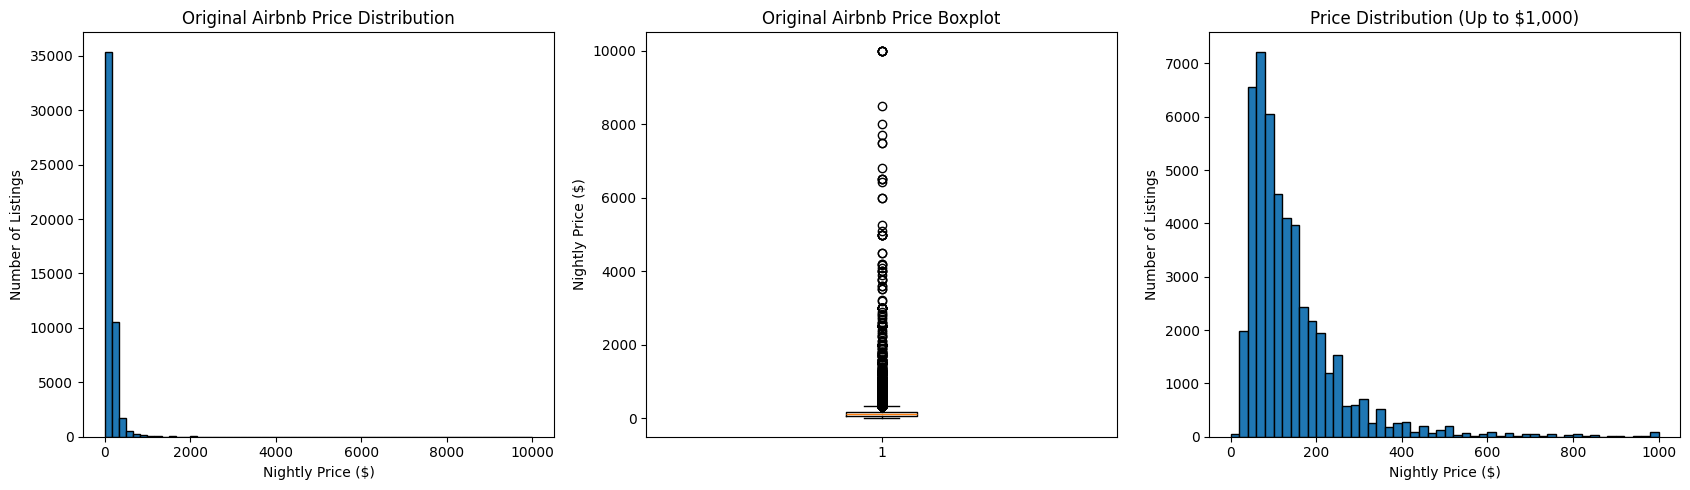

In [11]:
import matplotlib.pyplot as plt

# Create separate visualizations
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Original price histogram
axes[0].hist(
    df_airbnb["price"],
    bins=60,
    edgecolor="black"
)
axes[0].set_title("Original Airbnb Price Distribution")
axes[0].set_xlabel("Nightly Price ($)")
axes[0].set_ylabel("Number of Listings")

# 2. Original price boxplot
axes[1].boxplot(
    df_airbnb["price"],
    vert=True
)
axes[1].set_title("Original Airbnb Price Boxplot")
axes[1].set_ylabel("Nightly Price ($)")

# 3. Zoomed histogram (visualization only)
axes[2].hist(
    df_airbnb.loc[df_airbnb["price"] <= 1000, "price"],
    bins=50,
    edgecolor="black"
)
axes[2].set_title("Price Distribution (Up to $1,000)")
axes[2].set_xlabel("Nightly Price ($)")
axes[2].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()

## 4. Outlier Detection Using the IQR Method

The Interquartile Range (IQR) measures the spread of
the middle 50% of the data.

IQR = Q3 - Q1

The standard 1.5 × IQR rule defines the boundaries:

- Lower Bound = Q1 - 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

For the original Airbnb prices:

- Q1 = $69
- Q3 = $175
- IQR = $106
- Lower Bound = -$90
- Upper Bound = $334

Prices outside these boundaries are flagged as
potential statistical outliers.

Before applying the method, zero or negative prices
are excluded because the analysis concerns paid
nightly accommodation.

The IQR method is relatively resistant to extreme
values because it uses quartiles instead of the mean.

In [12]:
# -------------------------------------
# 1. Remove invalid prices
# -------------------------------------

df_valid = df_airbnb[
    df_airbnb["price"] > 0
].copy()

print("Original listings:", len(df_airbnb))
print("Valid-price listings:", len(df_valid))
print("Invalid-price listings removed:",
      len(df_airbnb) - len(df_valid))


# -------------------------------------
# 2. Calculate IQR on valid prices
# -------------------------------------

Q1 = df_valid["price"].quantile(0.25)
Q3 = df_valid["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("\nIQR Statistical Measures:")
print(f"Q1: ${Q1:.2f}")
print(f"Q3: ${Q3:.2f}")
print(f"IQR: ${IQR:.2f}")
print(f"Lower Bound: ${lower_bound:.2f}")
print(f"Upper Bound: ${upper_bound:.2f}")


# -------------------------------------
# 3. Identify statistical outliers
# -------------------------------------

outlier_mask = (
    (df_valid["price"] < lower_bound) |
    (df_valid["price"] > upper_bound)
)

df_iqr_outliers = df_valid[outlier_mask].copy()

df_iqr_clean = df_valid[~outlier_mask].copy()

print("\nIQR Outlier Detection Results:")
print("Statistical outliers found:",
      len(df_iqr_outliers))

print("Listings remaining after IQR:",
      len(df_iqr_clean))

print(
    "Percentage of valid listings flagged:",
    round(len(df_iqr_outliers) / len(df_valid) * 100, 2),
    "%"
)


# -------------------------------------
# 4. Compare original and cleaned prices
# -------------------------------------

comparison = pd.DataFrame({
    "Original Valid Prices": df_valid["price"].describe(),
    "IQR Cleaned Prices": df_iqr_clean["price"].describe()
})

print("\nBefore vs After IQR Cleaning:")
display(comparison.round(2))

# Verify retained prices satisfy original IQR bounds
assert df_iqr_clean["price"].between(
    lower_bound, upper_bound
).all()

print("\nVerification: All retained prices are within the IQR bounds.")

Original listings: 48895
Valid-price listings: 48884
Invalid-price listings removed: 11

IQR Statistical Measures:
Q1: $69.00
Q3: $175.00
IQR: $106.00
Lower Bound: $-90.00
Upper Bound: $334.00

IQR Outlier Detection Results:
Statistical outliers found: 2972
Listings remaining after IQR: 45912
Percentage of valid listings flagged: 6.08 %

Before vs After IQR Cleaning:


,Original Valid Prices,IQR Cleaned Prices
count,48884.00,45912.00
mean,152.76,120.00
std,240.17,68.13
min,10.00,10.00
25%,69.00,65.00
50%,106.00,100.00
75%,175.00,159.00
max,10000.00,334.00



Verification: All retained prices are within the IQR bounds.


## 5. Outlier Detection Using Mean, Standard Deviation,
and Z-Score

The Z-score measures how far an observation is from
the mean in units of standard deviation.

The formula is:

$$
Z = \frac{x - \mu}{\sigma}
$$

Where:

- x = Individual nightly price
- μ = Mean nightly price
- σ = Standard deviation

For this analysis, prices with an absolute Z-score
greater than 3 are considered potential outliers.

This method uses the mean and standard deviation to
identify unusually high or low nightly prices.

**Limitation:**

The Airbnb prices are strongly right-skewed.
Extremely expensive listings influence both the mean
and standard deviation, potentially making the
Z-score method less effective at identifying
moderately high-price outliers.

The results will be compared with the IQR method.

In [13]:
# -------------------------------------
# 1. Calculate mean and standard deviation
# -------------------------------------

mean_price = df_valid["price"].mean()
std_price = df_valid["price"].std(ddof=0)

print("Mean Price:", round(mean_price, 2))
print("Standard Deviation:", round(std_price, 2))


# -------------------------------------
# 2. Calculate Z-scores
# -------------------------------------

z_scores = (
    (df_valid["price"] - mean_price) / std_price
)

# Set the threshold
z_threshold = 3

# Identify outliers
z_outlier_mask = z_scores.abs() > z_threshold

df_zscore_outliers = df_valid[z_outlier_mask].copy()
df_zscore_clean = df_valid[~z_outlier_mask].copy()


# -------------------------------------
# 3. Display results
# -------------------------------------

print("\nZ-Score Outlier Detection:")

print("Outliers Found:", len(df_zscore_outliers))
print("Cleaned Listings:", len(df_zscore_clean))

print(
    "Percentage Removed:",
    round(
        len(df_zscore_outliers) / len(df_valid) * 100,
        2
    ),
    "%"
)

# Calculate boundaries
z_lower = mean_price - 3 * std_price
z_upper = mean_price + 3 * std_price

print(f"\nLower Boundary: ${z_lower:.2f}")
print(f"Upper Boundary: ${z_upper:.2f}")


# -------------------------------------
# 4. Compare before and after
# -------------------------------------

z_comparison = pd.DataFrame({
    "Original Valid Prices": df_valid["price"].describe(),
    "Z-Score Cleaned Prices": df_zscore_clean["price"].describe()
})

print("\nBefore vs After Z-Score Cleaning:")
display(z_comparison.round(2))


# -------------------------------------
# 5. Verify filtering
# -------------------------------------

assert (z_scores.loc[df_zscore_clean.index].abs() <= 3).all()

print("\nVerification: All retained prices are within the original Z-score threshold.")

Mean Price: 152.76
Standard Deviation: 240.17

Z-Score Outlier Detection:
Outliers Found: 388
Cleaned Listings: 48496
Percentage Removed: 0.79 %

Lower Boundary: $-567.75
Upper Boundary: $873.26

Before vs After Z-Score Cleaning:


,Original Valid Prices,Z-Score Cleaned Prices
count,48884.00,48496.00
mean,152.76,138.78
std,240.17,107.55
min,10.00,10.00
25%,69.00,69.00
50%,106.00,105.00
75%,175.00,175.00
max,10000.00,860.00



Verification: All retained prices are within the original Z-score threshold.


## 6. Outlier Detection Using Median Absolute Deviation (MAD)

Median Absolute Deviation (MAD) is a robust statistical
measure of dispersion.

Unlike standard deviation, MAD uses the median as its
central reference point.

The formula is:

$$
MAD = \operatorname{median}(|x_i - \operatorname{median}(x)|)
$$

A modified Z-score is calculated as:

$$
M_i = \frac{0.6745(x_i - \operatorname{median}(x))}{MAD}
$$

Observations with an absolute modified Z-score
greater than 3.5 are flagged as potential outliers.

**Why use MAD?**

Airbnb prices are strongly right-skewed. MAD is less
sensitive to extremely expensive listings than the
mean and standard deviation.

This method provides another way to identify unusual
nightly prices without relying on a normal distribution.

In [14]:
# -------------------------------------
# 1. Calculate median and MAD
# -------------------------------------

median_price = df_valid["price"].median()

absolute_deviations = (
    df_valid["price"] - median_price
).abs()

mad = absolute_deviations.median()

print(f"Median Price: ${median_price:.2f}")
print(f"Median Absolute Deviation: ${mad:.2f}")

# -------------------------------------
# 2. Calculate modified Z-scores
# -------------------------------------

if mad == 0:
    raise ValueError("MAD is zero; this method cannot be applied.")

modified_z_scores = (
    0.6745 * (df_valid["price"] - median_price) / mad
)

mad_threshold = 3.5

mad_outlier_mask = modified_z_scores.abs() > mad_threshold

# -------------------------------------
# 3. Create cleaned and outlier datasets
# -------------------------------------

df_mad_outliers = df_valid[mad_outlier_mask].copy()
df_mad_clean = df_valid[~mad_outlier_mask].copy()

print("\nMAD Outlier Detection Results:")
print("Outliers Found:", len(df_mad_outliers))
print("Cleaned Listings:", len(df_mad_clean))

print(
    "Percentage Removed:",
    round(len(df_mad_outliers) / len(df_valid) * 100, 2),
    "%"
)

# -------------------------------------
# 4. Calculate original MAD boundaries
# -------------------------------------

mad_lower = median_price - (mad_threshold * mad / 0.6745)
mad_upper = median_price + (mad_threshold * mad / 0.6745)

print(f"\nLower Boundary: ${mad_lower:.2f}")
print(f"Upper Boundary: ${mad_upper:.2f}")

# -------------------------------------
# 5. Compare before and after
# -------------------------------------

mad_comparison = pd.DataFrame({
    "Original Valid Prices": df_valid["price"].describe(),
    "MAD Cleaned Prices": df_mad_clean["price"].describe()
})

print("\nBefore vs After MAD Cleaning:")
display(mad_comparison.round(2))

# -------------------------------------
# 6. Verify results
# -------------------------------------

assert (
    modified_z_scores.loc[df_mad_clean.index].abs()
    <= mad_threshold
).all()

print("\nVerification: All retained prices satisfy the original MAD threshold.")

Median Price: $106.00
Median Absolute Deviation: $46.00

MAD Outlier Detection Results:
Outliers Found: 2916
Cleaned Listings: 45968
Percentage Removed: 5.97 %

Lower Boundary: $-132.70
Upper Boundary: $344.70

Before vs After MAD Cleaning:


,Original Valid Prices,MAD Cleaned Prices
count,48884.00,45968.00
mean,152.76,120.27
std,240.17,68.52
min,10.00,10.00
25%,69.00,65.00
50%,106.00,100.00
75%,175.00,159.00
max,10000.00,344.00



Verification: All retained prices satisfy the original MAD threshold.


## 7. Outlier Detection Using Percentiles

Percentile-based filtering identifies unusually low
and high prices using selected percentile boundaries.

For this analysis:

- Lower boundary: 1st percentile
- Upper boundary: 99th percentile

Prices below the 1st percentile or above the 99th
percentile are flagged as potential outliers.

**Advantages:**

- Easy to calculate and understand.
- Does not assume a normal distribution.
- Limits the influence of extreme prices.

**Limitations:**

- The percentile thresholds are subjective.
- Genuine low-cost and luxury listings may be excluded.
- Percentile filtering does not guarantee that the
  resulting data contains no outliers under other
  statistical definitions.

The results will be compared with IQR, Z-score,
and Median Absolute Deviation (MAD).

In [15]:
# -------------------------------------
# 1. Calculate percentile boundaries
# -------------------------------------

percentile_lower = df_valid["price"].quantile(0.01)
percentile_upper = df_valid["price"].quantile(0.99)

print("Percentile-Based Boundaries:")
print(f"1st Percentile: ${percentile_lower:.2f}")
print(f"99th Percentile: ${percentile_upper:.2f}")


# -------------------------------------
# 2. Identify outliers
# -------------------------------------

percentile_outlier_mask = (
    (df_valid["price"] < percentile_lower) |
    (df_valid["price"] > percentile_upper)
)

df_percentile_outliers = df_valid[
    percentile_outlier_mask
].copy()

df_percentile_clean = df_valid[
    ~percentile_outlier_mask
].copy()


# -------------------------------------
# 3. Display results
# -------------------------------------

print("\nPercentile Outlier Detection Results:")

print("Outliers Found:", len(df_percentile_outliers))
print("Cleaned Listings:", len(df_percentile_clean))

print(
    "Percentage Removed:",
    round(
        len(df_percentile_outliers) / len(df_valid) * 100,
        2
    ),
    "%"
)

print("\nLow-Price Outliers:",
      (df_valid["price"] < percentile_lower).sum())

print("High-Price Outliers:",
      (df_valid["price"] > percentile_upper).sum())


# -------------------------------------
# 4. Before and after comparison
# -------------------------------------

percentile_comparison = pd.DataFrame({
    "Original Valid Prices": df_valid["price"].describe(),
    "Percentile Cleaned Prices": df_percentile_clean["price"].describe()
})

print("\nBefore vs After Percentile Cleaning:")
display(percentile_comparison.round(2))


# -------------------------------------
# 5. Verify cleaning
# -------------------------------------

assert df_percentile_clean["price"].between(
    percentile_lower, percentile_upper
).all()

print(
    "\nVerification: All retained prices satisfy "
    "the original percentile boundaries."
)

Percentile-Based Boundaries:
1st Percentile: $30.00
99th Percentile: $799.00

Percentile Outlier Detection Results:
Outliers Found: 867
Cleaned Listings: 48017
Percentage Removed: 1.77 %

Low-Price Outliers: 393
High-Price Outliers: 474

Before vs After Percentile Cleaning:


,Original Valid Prices,Percentile Cleaned Prices
count,48884.00,48017.00
mean,152.76,138.50
std,240.17,103.69
min,10.00,30.00
25%,69.00,70.00
50%,106.00,105.00
75%,175.00,175.00
max,10000.00,799.00



Verification: All retained prices satisfy the original percentile boundaries.


## 8. Comparison of Outlier Detection Methods

Four statistical methods were applied to the same
48,884 listings with valid positive nightly prices.

| Method | Outliers | Percentage Removed |
|---|---:|---:|
| IQR | 2,972 | 6.08% |
| Z-score | 388 | 0.79% |
| MAD | 2,916 | 5.97% |
| Percentiles | 867 | 1.77% |

### Observations

**IQR:**
Identified 2,972 outliers using quartiles.
It is relatively resistant to extreme values.

**Z-score:**
Identified only 388 outliers. The extremely high
prices increase the mean and standard deviation,
resulting in a relatively high upper boundary.

**MAD:**
Identified 2,916 outliers, close to the IQR result.
It is a robust alternative because it uses the
median and median absolute deviation.

**Percentiles:**
Identified 867 outliers using the 1st and 99th
percentile boundaries. Unlike the other methods,
it also removed unusually low-price listings.

### Interpretation

IQR and MAD are useful for strongly right-skewed
price distributions because their boundaries are
less influenced by extreme prices.

However, expensive Airbnb listings may be genuine.
Therefore, statistical outliers should not
automatically be considered incorrect data.

We will also examine prices by room type before
choosing the final cleaning strategy.

Outlier Detection Methods Comparison:


,Method,Listings,Outliers Removed,Removed (%),Mean Price,Median Price,Std Dev,Maximum Price
0,Original Valid Data,48884,0,0.00,152.76,106.0,240.17,10000
1,IQR,45912,2972,6.08,120.00,100.0,68.13,334
2,Z-Score,48496,388,0.79,138.78,105.0,107.55,860
3,MAD,45968,2916,5.97,120.27,100.0,68.52,344
4,Percentiles,48017,867,1.77,138.50,105.0,103.69,799


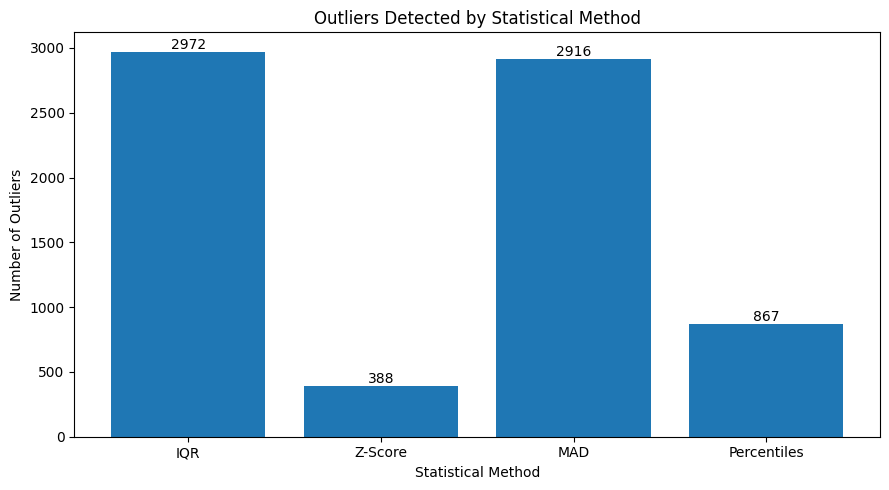

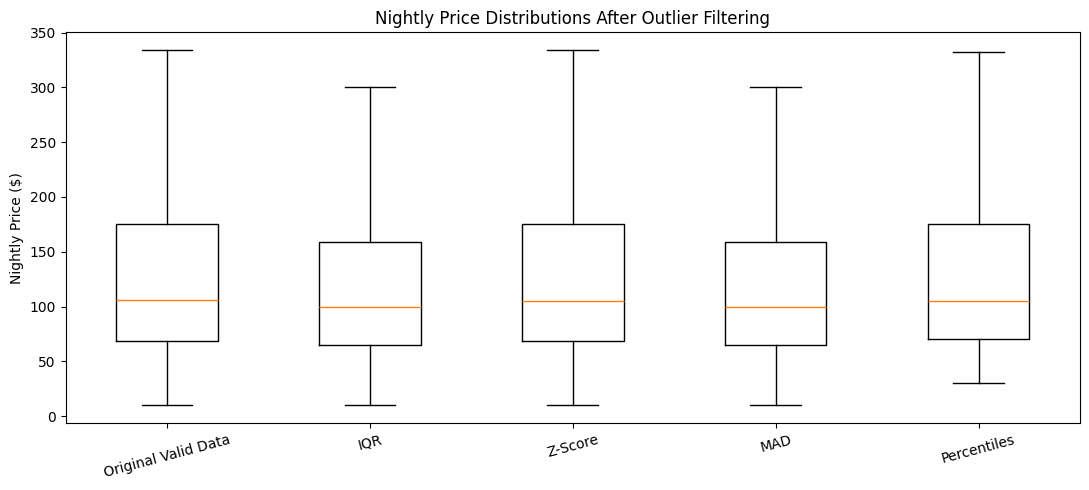

In [16]:
# -------------------------------------
# 1. Build comparison table
# -------------------------------------

methods = {
    "Original Valid Data": df_valid,
    "IQR": df_iqr_clean,
    "Z-Score": df_zscore_clean,
    "MAD": df_mad_clean,
    "Percentiles": df_percentile_clean
}

comparison_rows = []

for method, dataset in methods.items():
    removed = len(df_valid) - len(dataset)

    comparison_rows.append({
        "Method": method,
        "Listings": len(dataset),
        "Outliers Removed": removed,
        "Removed (%)": round(
            removed / len(df_valid) * 100, 2
        ),
        "Mean Price": round(dataset["price"].mean(), 2),
        "Median Price": round(dataset["price"].median(), 2),
        "Std Dev": round(dataset["price"].std(), 2),
        "Maximum Price": dataset["price"].max()
    })

methods_comparison_df = pd.DataFrame(comparison_rows)

print("Outlier Detection Methods Comparison:")
display(methods_comparison_df)


# -------------------------------------
# 2. Visualize outliers removed
# -------------------------------------

fig, ax = plt.subplots(figsize=(9, 5))

filtered_results = methods_comparison_df.iloc[1:]

bars = ax.bar(
    filtered_results["Method"],
    filtered_results["Outliers Removed"]
)

ax.bar_label(bars)

ax.set_title("Outliers Detected by Statistical Method")
ax.set_xlabel("Statistical Method")
ax.set_ylabel("Number of Outliers")

plt.tight_layout()
plt.show()


# -------------------------------------
# 3. Compare price distributions
# -------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

price_datasets = [
    dataset["price"].values
    for dataset in methods.values()
]

ax.boxplot(
    price_datasets,
    tick_labels=list(methods.keys()),
    showfliers=False
)

ax.set_title(
    "Nightly Price Distributions After Outlier Filtering"
)
ax.set_ylabel("Nightly Price ($)")

plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 9. Room-Type-Based Outlier Detection

Airbnb listings contain different types of accommodation,
including entire homes, private rooms, and shared rooms.

These accommodation types have different typical prices.

Applying one global price boundary may incorrectly classify
legitimate expensive apartments as outliers.

To address this limitation, the IQR method is applied
separately within each room type.

For each room type:

1. Calculate Q1 and Q3.
2. Calculate the IQR.
3. Determine lower and upper outlier boundaries.
4. Identify listings outside those boundaries.
5. Create a cleaned dataset.

This approach considers differences between
accommodation categories.

However, statistical outliers may still represent
legitimate premium or unusually inexpensive listings.

In [17]:
# -------------------------------------
# 1. Calculate IQR boundaries by room type
# -------------------------------------

room_type_stats = (
    df_valid.groupby("room_type")["price"]
    .agg(
        count="count",
        Q1=lambda x: x.quantile(0.25),
        median="median",
        Q3=lambda x: x.quantile(0.75)
    )
)

room_type_stats["IQR"] = (
    room_type_stats["Q3"] - room_type_stats["Q1"]
)

room_type_stats["Lower Bound"] = (
    room_type_stats["Q1"] - 1.5 * room_type_stats["IQR"]
)

room_type_stats["Upper Bound"] = (
    room_type_stats["Q3"] + 1.5 * room_type_stats["IQR"]
)

print("IQR Boundaries by Room Type:")
display(room_type_stats.round(2))


# -------------------------------------
# 2. Apply boundaries to each listing
# -------------------------------------

df_room_iqr = df_valid.join(
    room_type_stats[["Lower Bound", "Upper Bound"]],
    on="room_type"
)

room_outlier_mask = (
    (df_room_iqr["price"] < df_room_iqr["Lower Bound"]) |
    (df_room_iqr["price"] > df_room_iqr["Upper Bound"])
)

df_room_type_outliers = df_room_iqr[
    room_outlier_mask
].copy()

df_room_type_clean = df_room_iqr[
    ~room_outlier_mask
].copy()


# -------------------------------------
# 3. Display filtering results
# -------------------------------------

print("\nRoom-Type-Based IQR Results:")

print("Original valid listings:", len(df_valid))
print("Outliers detected:", len(df_room_type_outliers))
print("Cleaned listings:", len(df_room_type_clean))

print(
    "Percentage removed:",
    round(
        len(df_room_type_outliers) / len(df_valid) * 100,
        2
    ),
    "%"
)


# -------------------------------------
# 4. Results by accommodation type
# -------------------------------------

room_comparison = pd.DataFrame({
    "Original": df_valid.groupby("room_type").size(),
    "Cleaned": df_room_type_clean.groupby("room_type").size()
}).fillna(0).astype(int)

room_comparison["Outliers Removed"] = (
    room_comparison["Original"] -
    room_comparison["Cleaned"]
)

room_comparison["Removed (%)"] = (
    room_comparison["Outliers Removed"] /
    room_comparison["Original"] * 100
).round(2)

print("\nOutliers Removed by Room Type:")
display(room_comparison)


# -------------------------------------
# 5. Verify results
# -------------------------------------

assert df_room_type_clean["price"].between(
    df_room_type_clean["Lower Bound"],
    df_room_type_clean["Upper Bound"]
).all()

print(
    "\nVerification: All retained listings satisfy "
    "their room-type-specific IQR boundaries."
)

IQR Boundaries by Room Type:


,count,Q1,median,Q3,IQR,Lower Bound,Upper Bound
room_type,,,,,,,
Entire home/apt,25407,120.0,160.0,229.0,109.0,-43.5,392.5
Private room,22319,50.0,70.0,95.0,45.0,-17.5,162.5
Shared room,1158,33.0,45.0,75.0,42.0,-30.0,138.0



Room-Type-Based IQR Results:
Original valid listings: 48884
Outliers detected: 3244
Cleaned listings: 45640
Percentage removed: 6.64 %

Outliers Removed by Room Type:


,Original,Cleaned,Outliers Removed,Removed (%)
room_type,,,,
Entire home/apt,25407,23536,1871,7.36
Private room,22319,21029,1290,5.78
Shared room,1158,1075,83,7.17



Verification: All retained listings satisfy their room-type-specific IQR boundaries.


## 10. Final Cleaning Strategy

After comparing five statistical approaches, the
room-type-based IQR method was selected for the
final cleaned Airbnb dataset.

### Reason for Selection

Different Airbnb accommodation types have different
typical nightly prices.

A global IQR threshold applies the same price range
to entire apartments, private rooms, and shared rooms.

The room-type-based method calculates separate
outlier boundaries for each accommodation category.

This approach better accounts for differences in
accommodation prices.

### Final Cleaning Results

- Original listings: 48,895
- Invalid zero-price listings removed: 11
- Valid-price listings: 48,884
- Statistical outliers removed: 3,244
- Final cleaned listings: 45,640

### Important Limitation

The resulting dataset contains no prices outside
the original room-type-specific IQR boundaries.

However, this does not guarantee the absence of
outliers under every possible statistical method
or after recalculating IQR boundaries.

Some excluded expensive listings may represent
legitimate luxury accommodation.

In [18]:
# -------------------------------------
# 1. Prepare final cleaned dataset
# -------------------------------------

# Retain only the original dataset columns
df_final_clean = df_room_type_clean[
    df_airbnb.columns
].copy()

# Reset row index
df_final_clean = df_final_clean.reset_index(drop=True)


# -------------------------------------
# 2. Verify dataset
# -------------------------------------

print("Final Dataset Validation")
print("-" * 45)

print("Original listings:", len(df_airbnb))
print("Final cleaned listings:", len(df_final_clean))

print(
    "Total listings removed:",
    len(df_airbnb) - len(df_final_clean)
)

print("\nOriginal columns:", len(df_airbnb.columns))
print("Final columns:", len(df_final_clean.columns))

print("\nMinimum nightly price:",
      df_final_clean["price"].min())

print("Maximum nightly price:",
      df_final_clean["price"].max())


# -------------------------------------
# 3. Verify positive prices
# -------------------------------------

assert (df_final_clean["price"] > 0).all()

# Verify original columns are preserved
assert df_final_clean.columns.tolist() == df_airbnb.columns.tolist()

# Verify expected number of listings
assert len(df_final_clean) == 45640


# -------------------------------------
# 4. Verify room-type IQR boundaries
# -------------------------------------

validation_df = df_final_clean.join(
    room_type_stats[["Lower Bound", "Upper Bound"]],
    on="room_type"
)

valid_price_mask = (
    (validation_df["price"] >= validation_df["Lower Bound"]) &
    (validation_df["price"] <= validation_df["Upper Bound"])
)

assert valid_price_mask.all()

print("\nAll validation checks passed!")


# -------------------------------------
# 5. Export final dataset
# -------------------------------------

output_path = repo_dir / "students-submissions" / "9110715" / \
              "airbnb_cleaned.csv"

df_final_clean.to_csv(output_path, index=False)

print("\nCleaned dataset saved to:")
print(output_path)

print("\nFinal Price Summary:")
display(df_final_clean["price"].describe())

Final Dataset Validation
---------------------------------------------
Original listings: 48895
Final cleaned listings: 45640
Total listings removed: 3255

Original columns: 16
Final columns: 16

Minimum nightly price: 10
Maximum nightly price: 392

All validation checks passed!

Cleaned dataset saved to:
d:\Career\Conestoga\AI algorithms and mathimatics\week 2\Lab 1\CSCN8000-lab-submissions\students-submissions\9110715\airbnb_cleaned.csv

Final Price Summary:


count    45640.000000
mean       121.807406
std         73.232356
min         10.000000
25%         65.000000
50%        100.000000
75%        156.000000
max        392.000000
Name: price, dtype: float64

## 11. Final Dataset: Before-and-After Comparison

The final cleaned dataset was created using the
room-type-based IQR method.

A comparison of the original and cleaned datasets
helps demonstrate the effects of removing invalid
prices and statistical outliers.

The analysis compares:

- Nightly price distribution
- Median price
- Mean price
- Standard deviation
- Maximum price

The original dataset is preserved for comparison.

The cleaned dataset contains 45,640 listings, with
prices satisfying the original IQR boundaries
calculated separately for each room type.

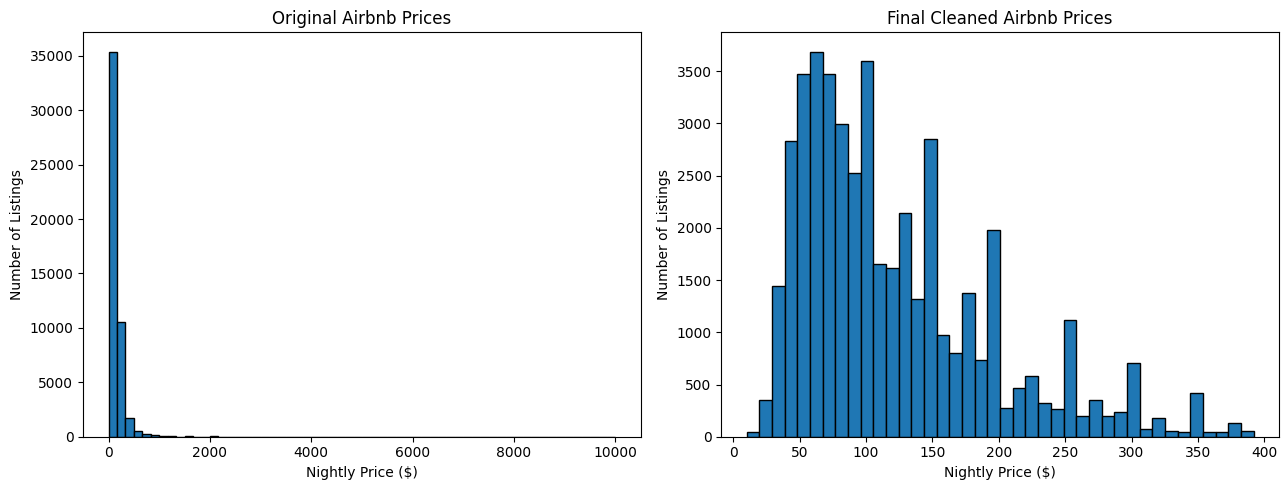

Final Before-and-After Comparison:


,Original Dataset,Cleaned Dataset
count,48895.00,45640.00
mean,152.72,121.81
std,240.15,73.23
min,0.00,10.00
25%,69.00,65.00
50%,106.00,100.00
75%,175.00,156.00
max,10000.00,392.00



Final verification completed successfully!


In [19]:
# -------------------------------------
# 1. Compare original and cleaned prices
# -------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Original dataset
axes[0].hist(
    df_airbnb["price"],
    bins=60,
    edgecolor="black"
)

axes[0].set_title("Original Airbnb Prices")
axes[0].set_xlabel("Nightly Price ($)")
axes[0].set_ylabel("Number of Listings")

# Final cleaned dataset
axes[1].hist(
    df_final_clean["price"],
    bins=40,
    edgecolor="black"
)

axes[1].set_title("Final Cleaned Airbnb Prices")
axes[1].set_xlabel("Nightly Price ($)")
axes[1].set_ylabel("Number of Listings")

plt.tight_layout()
plt.show()


# -------------------------------------
# 2. Compare summary statistics
# -------------------------------------

final_comparison = pd.DataFrame({
    "Original Dataset": df_airbnb["price"].describe(),
    "Cleaned Dataset": df_final_clean["price"].describe()
})

print("Final Before-and-After Comparison:")
display(final_comparison.round(2))


# -------------------------------------
# 3. Verify retained listing IDs
# -------------------------------------

assert df_final_clean["id"].isin(df_airbnb["id"]).all()

print("\nFinal verification completed successfully!")

## 12. Part B — Final Conclusion

In Part B, the New York City Airbnb dataset was analyzed
to identify and remove unusual nightly prices using
statistical measures of central tendency and dispersion.

### Dataset Exploration

The original dataset contained 48,895 listings and
16 columns.

The mean nightly price was $152.72, while the median
was $106. This difference indicated a strongly
right-skewed price distribution.

The original maximum price was $10,000.

Eleven listings with zero nightly prices were
excluded because the analysis focused on paid
accommodation.

### Outlier Detection Methods

Five statistical approaches were demonstrated:

| Method | Outliers Detected |
|---|---:|
| Global IQR | 2,972 |
| Z-score | 388 |
| Median Absolute Deviation (MAD) | 2,916 |
| 1st–99th Percentiles | 867 |
| Room-Type-Based IQR | 3,244 |

All five methods were applied to the same 48,884
valid-price listings.

IQR and MAD identified more high-price outliers
than the Z-score method because they are less
sensitive to extreme values.

Percentile filtering identified both unusually
low and high prices.

### Selected Cleaning Method

Room-type-based IQR was selected because entire
homes, private rooms, and shared rooms have
different typical nightly prices.

Instead of applying one price boundary to all
listings, this method calculates separate IQR
boundaries for each accommodation type.

The method removed 3,244 statistical outliers
from the valid-price dataset.

### Final Cleaned Dataset

The final dataset contains:

- 45,640 Airbnb listings
- 16 original columns
- Minimum nightly price: $10
- Maximum nightly price: $392
- Mean nightly price: $121.81
- Median nightly price: $100
- Standard deviation: $73.23

A total of 3,255 records were excluded from the
original dataset, including 11 zero-price listings.

The cleaned dataset was exported as
`airbnb_cleaned.csv`.

### Limitations

Statistical outliers are not necessarily incorrect
observations. Some expensive Airbnb listings
may represent legitimate luxury accommodation.

The final dataset satisfies the original
room-type-specific IQR boundaries.

However, recalculating statistical boundaries
on the cleaned dataset may identify additional
outliers.

Missing review information was retained because
it was not required for price outlier analysis.

### Final Observation

This analysis demonstrates how the mean, median,
standard deviation, quartiles, percentiles,
and robust statistical techniques can be used
to investigate unusual values.

Selecting an appropriate outlier-detection
method requires considering the distribution
of the data and the context of the observations.